# EconoCausal: Exploratory Data Analysis

**Goal of this EDA:** understand the data *before* running Double Machine Learning.
For a causal project the key questions are different from a normal ML EDA:

1. What do the features look like? (Sections 2 to 3)
2. Who got which discount, and how did they respond? (Section 4)
3. Is there **confounding**: did the old targeting rule give discounts to different kinds of customers? (Section 5)
4. Is there **overlap**: can every kind of customer receive every discount? (Section 6)
5. How wrong is a **naive** comparison, compared with the randomized (RCT) benchmark and the simulated truth? (Section 7)
6. Does the discount effect **differ across customers** (heterogeneity)? (Section 8)
7. What do the ground-truth segments look like? (Section 9)

**Files needed:** `econocausal_observational.csv` and `econocausal_rct.csv`.
In **Google Colab** the notebook will ask you to upload them. In **Jupyter** put them in the same folder as this notebook.

## 0. Setup and loading

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

FILES = ["econocausal_observational.csv", "econocausal_rct.csv"]

# Google Colab: upload the files if they are not already there
if "google.colab" in sys.modules and not all(os.path.exists(f) for f in FILES):
    from google.colab import files
    print("Please upload BOTH csv files")
    files.upload()

obs = pd.read_csv("econocausal_observational.csv")
rct = pd.read_csv("econocausal_rct.csv")
print("Observational:", obs.shape, "| RCT:", rct.shape)

Observational: (100000, 30) | RCT: (20000, 30)


In [2]:
# Column groups used throughout the notebook
T = "discount_usd"                      # treatment
Y = "purchase"                          # outcome
NUM = ["age", "income_k", "tenure_months", "frequency_12m", "recency_days",
       "avg_basket", "monetary_12m", "past_coupon_rate", "campaign_month"]
CAT = ["loyalty_tier", "device", "channel", "region"]
FEATURES = NUM + CAT
BUSINESS = ["order_value", "margin_rate", "gross_margin", "discount_cost", "net_profit"]
GT = [c for c in obs.columns if c.startswith("gt_")]   # ground truth: evaluation only, never features
print("Treatment:", T, "| Outcome:", Y)
print("Features :", FEATURES)
print("Ground truth (do NOT use as features):", GT)

Treatment: discount_usd | Outcome: purchase
Features : ['age', 'income_k', 'tenure_months', 'frequency_12m', 'recency_days', 'avg_basket', 'monetary_12m', 'past_coupon_rate', 'campaign_month', 'loyalty_tier', 'device', 'channel', 'region']
Ground truth (do NOT use as features): ['gt_p_no_discount', 'gt_p_10', 'gt_p_20', 'gt_ite_10', 'gt_ite_20', 'gt_segment', 'gt_propensity_0', 'gt_propensity_10', 'gt_propensity_20']


## 1. Data overview

In [3]:
obs.head()

,customer_id,age,income_k,tenure_months,frequency_12m,recency_days,avg_basket,monetary_12m,past_coupon_rate,loyalty_tier,device,channel,region,campaign_month,discount_usd,purchase,order_value,margin_rate,gross_margin,discount_cost,net_profit,gt_p_no_discount,gt_p_10,gt_p_20,gt_ite_10,gt_ite_20,gt_segment,gt_propensity_0,gt_propensity_10,gt_propensity_20
0,C100000,42,24.1,115,0,51,38.55,0.00,0.124,Gold,mobile,email,North,12,10,0,0.00,0.295,0.00,0.0,0.00,0.2599,0.2874,0.3023,0.0275,0.0424,Lost Cause,0.7251,0.1963,0.0786
1,C100001,26,143.8,18,1,1,30.34,30.34,0.379,Silver,mobile,organic,North,9,0,0,0.00,0.499,0.00,0.0,0.00,0.1377,0.1558,0.1670,0.0182,0.0293,Lost Cause,0.7313,0.1805,0.0882
2,C100002,47,110.0,22,2,50,39.58,79.16,0.346,Silver,mobile,organic,North,10,20,0,0.00,0.431,0.00,0.0,0.00,0.0863,0.1068,0.1193,0.0205,0.0330,Lost Cause,0.5369,0.2744,0.1887
3,C100003,49,33.8,22,4,65,63.50,254.00,0.111,Bronze,desktop,paid_search,West,2,20,1,66.43,0.433,28.76,20.0,8.76,0.1280,0.1773,0.2075,0.0493,0.0795,Lost Cause,0.5962,0.2601,0.1437
4,C100004,18,100.8,12,7,17,50.90,356.30,0.087,Bronze,mobile,referral,East,11,0,0,0.00,0.334,0.00,0.0,0.00,0.3897,0.4015,0.4088,0.0118,0.0191,Lost Cause,0.7688,0.1698,0.0615


In [4]:
summary = pd.DataFrame({
    "dtype": obs.dtypes.astype(str),
    "missing": obs.isna().sum(),
    "unique": obs.nunique(),
})
display(summary)
print("Duplicate rows (obs):", obs.duplicated().sum(), "| Duplicate customer_ids:", obs.customer_id.duplicated().sum())
print("Duplicate rows (rct):", rct.duplicated().sum())

,dtype,missing,unique
customer_id,str,0,100000
age,int64,0,58
income_k,float64,0,1751
tenure_months,int64,0,120
frequency_12m,int64,0,33
recency_days,int64,0,312
avg_basket,float64,0,8009
monetary_12m,float64,0,29865
past_coupon_rate,float64,0,940
loyalty_tier,str,0,3


Duplicate rows (obs): 0 | Duplicate customer_ids: 0
Duplicate rows (rct): 0


In [5]:
obs[NUM + [Y, T]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,100000.0,38.190,11.524,18.0,30.000,38.000,46.000,75.000
income_k,100000.0,54.335,25.842,12.0,36.200,49.100,66.500,250.000
tenure_months,100000.0,30.717,20.504,1.0,16.000,26.000,41.000,120.000
frequency_12m,100000.0,4.399,3.733,0.0,2.000,4.000,6.000,32.000
recency_days,100000.0,34.569,35.729,1.0,10.000,23.000,47.000,365.000
avg_basket,100000.0,39.899,15.101,8.0,29.208,37.250,47.580,202.220
monetary_12m,100000.0,175.552,172.710,0.0,56.720,128.390,239.820,3107.720
past_coupon_rate,100000.0,0.305,0.179,0.0,0.164,0.279,0.421,0.994
campaign_month,100000.0,6.511,3.450,1.0,4.000,7.000,9.000,12.000
purchase,100000.0,0.301,0.459,0.0,0.000,0.000,1.000,1.000


**What to look for:** no missing values and no duplicates means we can go straight to analysis.
Note that `frequency_12m`, `recency_days`, and `monetary_12m` are skewed, which is normal for customer data.

## 2. Feature distributions (observational data)

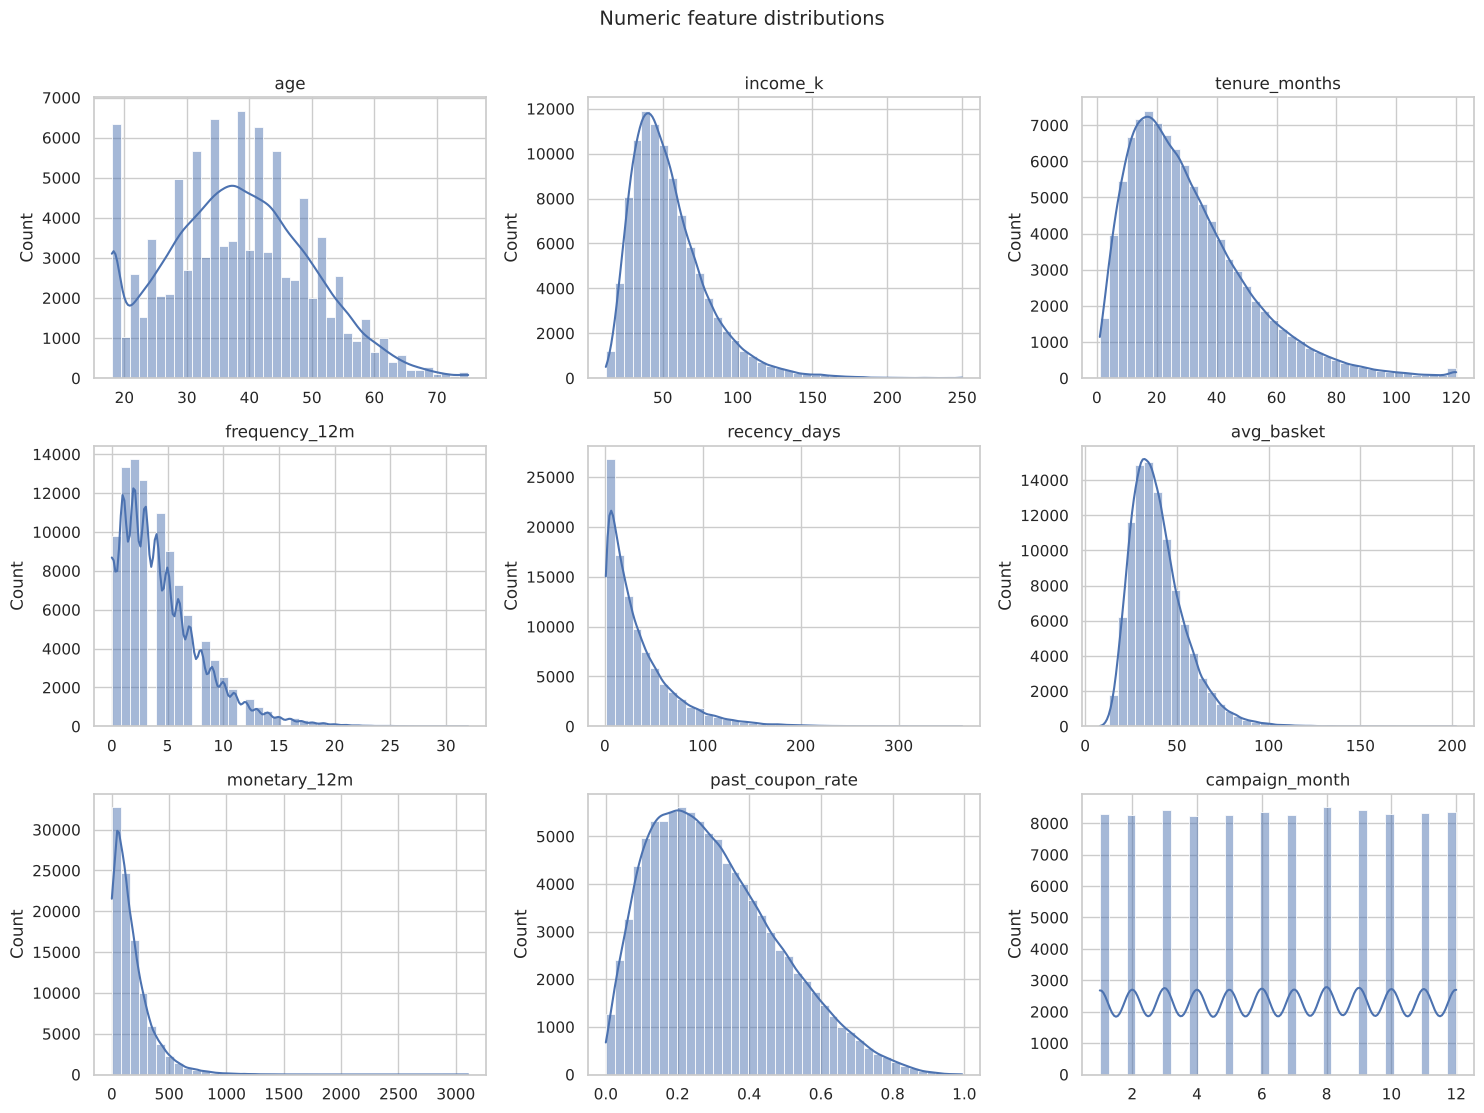

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), NUM):
    sns.histplot(obs[col], bins=40, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Numeric feature distributions", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

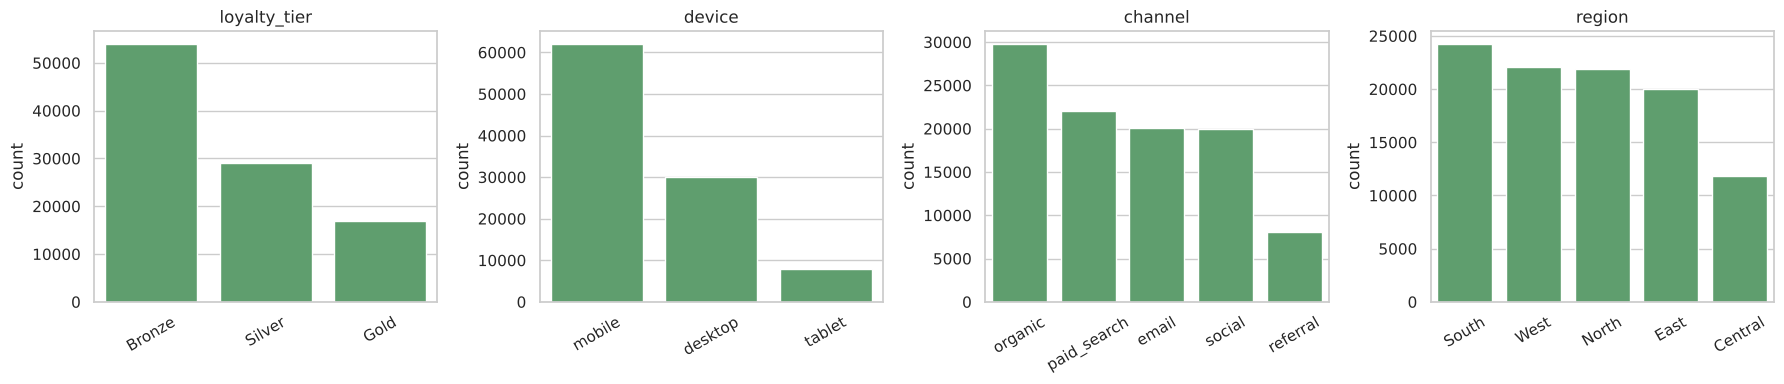

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, CAT):
    order = obs[col].value_counts().index
    sns.countplot(data=obs, x=col, order=order, ax=ax, color="#55A868")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 3. Relationships between features

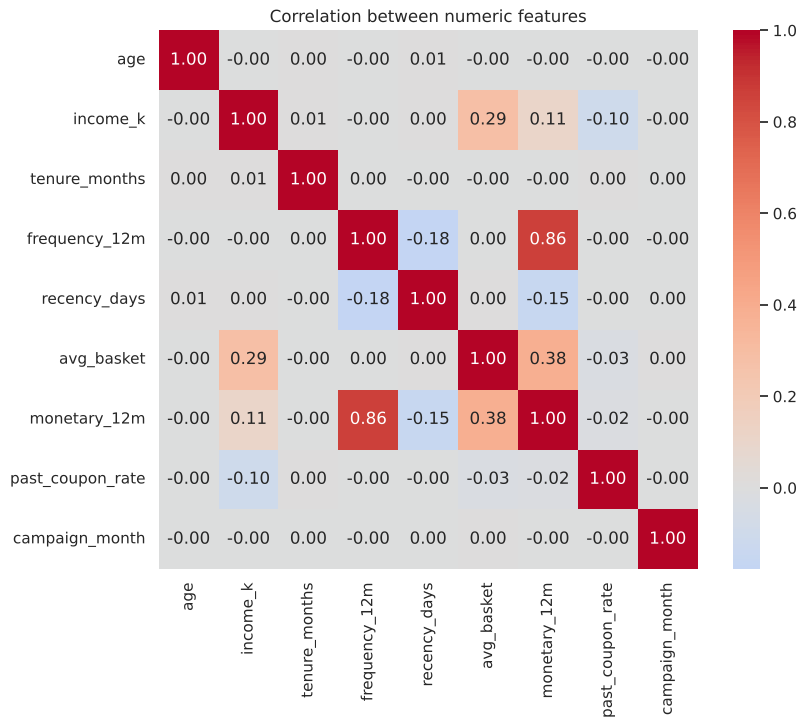

In [8]:
corr = obs[NUM].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation between numeric features")
plt.show()

Strong correlations (e.g. `monetary_12m` with `frequency_12m`) are expected because `monetary_12m = frequency_12m x avg_basket`.
DML with flexible models (random forests, gradient boosting) handles correlated features well, but keep this in mind when you interpret linear coefficients.

## 4. Treatment and outcome

,observational,rct
discount_usd,,
0,59.4,33.1
10,24.3,33.2
20,16.3,33.6


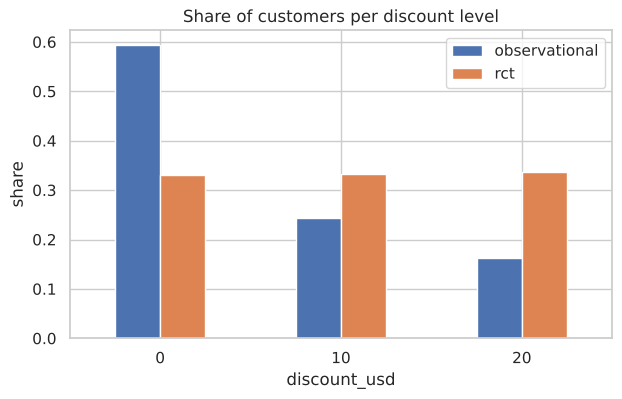

In [9]:
# 4.1 How many customers got each discount?
t_obs = obs[T].value_counts(normalize=True).sort_index().rename("observational")
t_rct = rct[T].value_counts(normalize=True).sort_index().rename("rct")
shares = pd.concat([t_obs, t_rct], axis=1)
display((shares * 100).round(1).rename_axis("discount_usd"))

shares.plot(kind="bar", figsize=(7, 4), color=["#4C72B0", "#DD8452"])
plt.title("Share of customers per discount level")
plt.ylabel("share"); plt.xticks(rotation=0)
plt.show()

,observational,rct
discount_usd,,
0,0.2692,0.2516
10,0.3452,0.3402
20,0.3512,0.3899


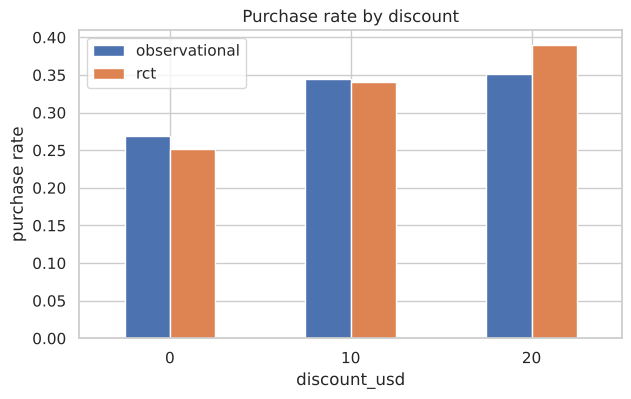

In [10]:
# 4.2 Purchase rate per discount arm
rates = pd.concat([
    obs.groupby(T)[Y].mean().rename("observational"),
    rct.groupby(T)[Y].mean().rename("rct"),
], axis=1)
display(rates.round(4))

rates.plot(kind="bar", figsize=(7, 4), color=["#4C72B0", "#DD8452"])
plt.title("Purchase rate by discount")
plt.ylabel("purchase rate"); plt.xticks(rotation=0)
plt.show()

**Important:** the observational purchase rates are *not* causal effects, because the customers in each arm are different people.
Only the RCT bars can be read as "what the discount does". Compare the two in Section 7.

In [11]:
# 4.3 Money view: profit after paying for the discount
money = obs.groupby(T)[["purchase", "order_value", "gross_margin", "discount_cost", "net_profit"]].mean().round(3)
display(money)

,purchase,order_value,gross_margin,discount_cost,net_profit
discount_usd,,,,,
0,0.269,11.428,4.346,0.000,4.346
10,0.345,15.044,5.730,3.452,2.278
20,0.351,14.921,5.667,7.024,-1.357


Average net profit per customer *includes* the discount cost. A discount that raises purchases can still lose money if the extra margin does not cover the cost.
This is exactly why the optimizer later needs **individual** effects instead of averages.

## 5. Confounding check: did different customers get different discounts?

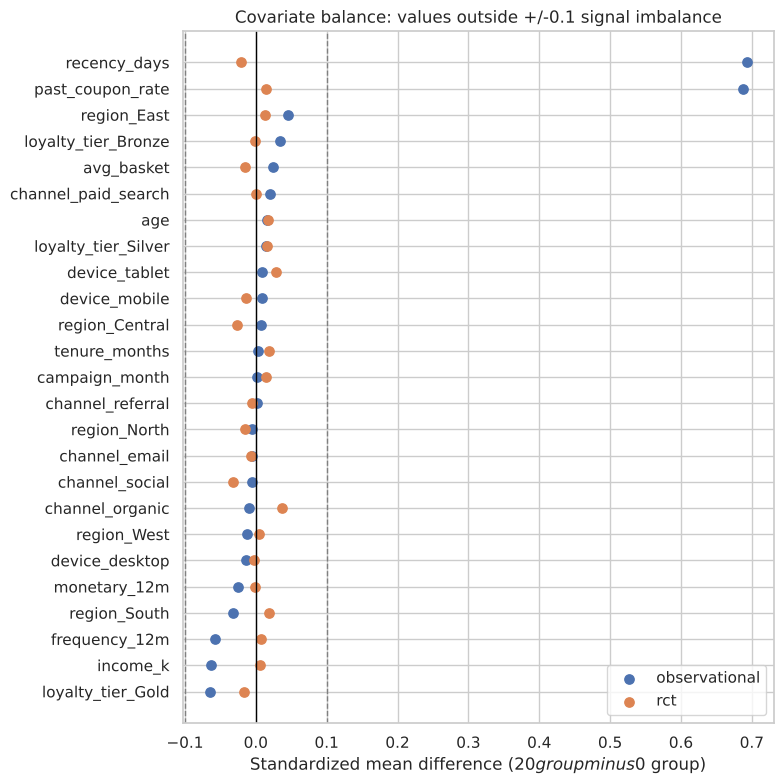

,observational,rct
loyalty_tier_Gold,-0.065,-0.017
income_k,-0.063,0.007
frequency_12m,-0.057,0.008
region_South,-0.032,0.019
monetary_12m,-0.025,-0.002
device_desktop,-0.014,-0.002
channel_paid_search,0.020,-0.000
avg_basket,0.025,-0.015
loyalty_tier_Bronze,0.034,-0.001
region_East,0.045,0.013


In [12]:
def one_hot(df):
    X = pd.get_dummies(df[FEATURES], columns=CAT, dtype=float)
    return X

def smd(df, a, b):
    X = one_hot(df)
    xa, xb = X[df[T] == a], X[df[T] == b]
    sd = np.sqrt((xa.var() + xb.var()) / 2).replace(0, np.nan)
    return ((xb.mean() - xa.mean()) / sd).dropna()

smd_obs = smd(obs, 0, 20).rename("observational")
smd_rct = smd(rct, 0, 20).rename("rct")
smd_df = pd.concat([smd_obs, smd_rct], axis=1).sort_values("observational")

fig, ax = plt.subplots(figsize=(8, 8))
y = np.arange(len(smd_df))
ax.scatter(smd_df["observational"], y, label="observational", color="#4C72B0", s=45)
ax.scatter(smd_df["rct"], y, label="rct", color="#DD8452", s=45)
ax.axvline(0, color="black", lw=1)
ax.axvline(0.1, color="grey", ls="--", lw=1); ax.axvline(-0.1, color="grey", ls="--", lw=1)
ax.set_yticks(y); ax.set_yticklabels(smd_df.index)
ax.set_xlabel("Standardized mean difference ($20 group minus $0 group)")
ax.set_title("Covariate balance: values outside +/-0.1 signal imbalance")
ax.legend()
plt.tight_layout(); plt.show()

display(pd.concat([smd_df.round(3).head(6), smd_df.round(3).tail(6)]))

**How to read this:** a standardized mean difference (SMD) near 0 means the two groups look alike on that feature.
In the RCT all dots sit near 0 (random assignment). In the observational data, features such as `recency_days` and `past_coupon_rate` are far from 0:
the old rule gave bigger discounts to lapsed, coupon-friendly customers. That is **confounding**, and it is why DML and propensity methods are needed.

In [13]:
# Same story, in raw numbers for the key confounders
key = ["recency_days", "past_coupon_rate", "monetary_12m", "frequency_12m"]
display(obs.groupby(T)[key].mean().round(2))
display(rct.groupby(T)[key].mean().round(2))

,recency_days,past_coupon_rate,monetary_12m,frequency_12m
discount_usd,,,,
0,26.88,0.27,171.16,4.36
10,39.80,0.34,192.03,4.66
20,54.76,0.39,166.98,4.15


,recency_days,past_coupon_rate,monetary_12m,frequency_12m
discount_usd,,,,
0,35.37,0.3,175.40,4.37
10,34.40,0.3,174.22,4.39
20,34.63,0.3,175.09,4.40


## 6. Overlap (positivity) check

Estimated propensity range per arm:


,p_0,p_10,p_20
min,0.001,0.078,0.018
25%,0.484,0.185,0.075
50%,0.633,0.240,0.124
75%,0.737,0.298,0.212
max,0.895,0.778,0.921


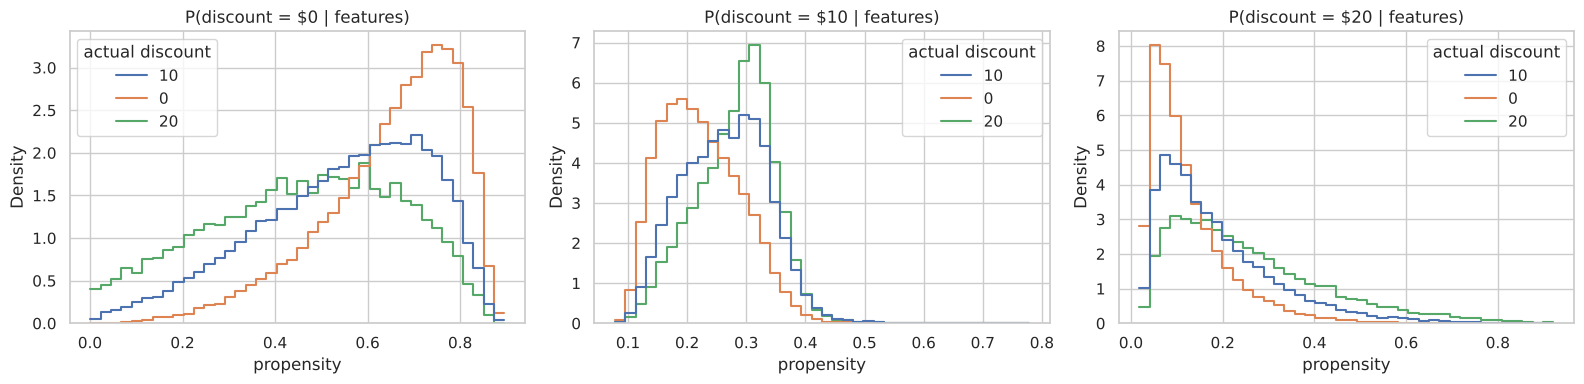

In [14]:
# Estimate propensity scores P(T = t | X) with a simple multinomial logistic regression
X = one_hot(obs)
Xs = StandardScaler().fit_transform(X)
clf = LogisticRegression(max_iter=2000)
clf.fit(Xs, obs[T])
prop = pd.DataFrame(clf.predict_proba(Xs), columns=[f"p_{c}" for c in clf.classes_])
print("Estimated propensity range per arm:")
display(prop.describe().loc[["min", "25%", "50%", "75%", "max"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, t in zip(axes, [0, 10, 20]):
    d = pd.DataFrame({"propensity": prop[f"p_{t}"], "actual discount": obs[T].astype(str)})
    sns.histplot(data=d, x="propensity", hue="actual discount", bins=40, stat="density",
                 common_norm=False, element="step", fill=False, ax=ax)
    ax.set_title(f"P(discount = ${t} | features)")
plt.tight_layout(); plt.show()

**How to read this:** for each plot, the curves of the *treated* and *untreated* groups should overlap over most of the range.
Where only one group lives (a region with no overlap), causal estimates are unreliable because we never saw comparable customers who got the other discount.
Because the data has propensities bounded away from 0, overlap here is acceptable. You can still trim extreme propensities in the model later.

In [15]:
# Because the data is simulated, we can compare with the TRUE propensity used to assign discounts
chk = pd.DataFrame({"estimated_p20": prop["p_20"], "true_p20": obs["gt_propensity_20"]})
print("Correlation between estimated and true propensity for $20:", round(chk.corr().iloc[0, 1], 3))

Correlation between estimated and true propensity for $20: 0.999


## 7. Naive effect vs RCT effect vs the true effect

,naive (observational),RCT estimate,RCT 95% low,RCT 95% high,TRUE average effect
discount,,,,,
$10,0.076,0.0885,0.0731,0.1040,0.0794
$20,0.082,0.1383,0.1226,0.1539,0.1279


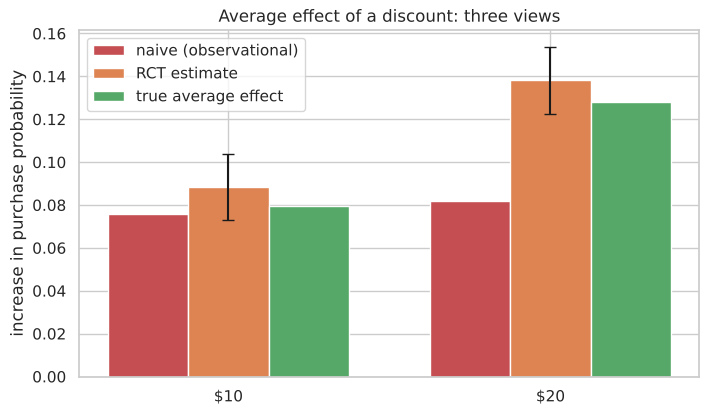

In [16]:
def diff_in_means(df, arm):
    a = df[df[T] == 0][Y]; b = df[df[T] == arm][Y]
    d = b.mean() - a.mean()
    se = np.sqrt(a.var() / len(a) + b.var() / len(b))
    return d, d - 1.96 * se, d + 1.96 * se

rows = []
for arm in [10, 20]:
    n_d, n_lo, n_hi = diff_in_means(obs, arm)
    r_d, r_lo, r_hi = diff_in_means(rct, arm)
    rows.append({"discount": f"${arm}",
                 "naive (observational)": n_d,
                 "RCT estimate": r_d, "RCT 95% low": r_lo, "RCT 95% high": r_hi,
                 "TRUE average effect": obs[f"gt_ite_{arm}"].mean()})
effects = pd.DataFrame(rows).set_index("discount")
display(effects.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(effects)); w = 0.25
ax.bar(x - w, effects["naive (observational)"], w, label="naive (observational)", color="#C44E52")
ax.bar(x, effects["RCT estimate"], w, label="RCT estimate",
       yerr=[effects["RCT estimate"] - effects["RCT 95% low"], effects["RCT 95% high"] - effects["RCT estimate"]],
       capsize=4, color="#DD8452")
ax.bar(x + w, effects["TRUE average effect"], w, label="true average effect", color="#55A868")
ax.set_xticks(x); ax.set_xticklabels(effects.index)
ax.set_ylabel("increase in purchase probability")
ax.set_title("Average effect of a discount: three views")
ax.legend()
plt.show()

**Key finding to put in your report:** the naive comparison on the observational data understates (or misstates) the effect of the larger discount,
because discounts went to customers who were already less likely to buy. The RCT and the simulated truth agree with each other.
**Your DML model, trained only on the observational file, should land close to the RCT/true numbers.** That is the proof that it works.

## 8. Does the effect differ across customers? (heterogeneity, from the RCT)

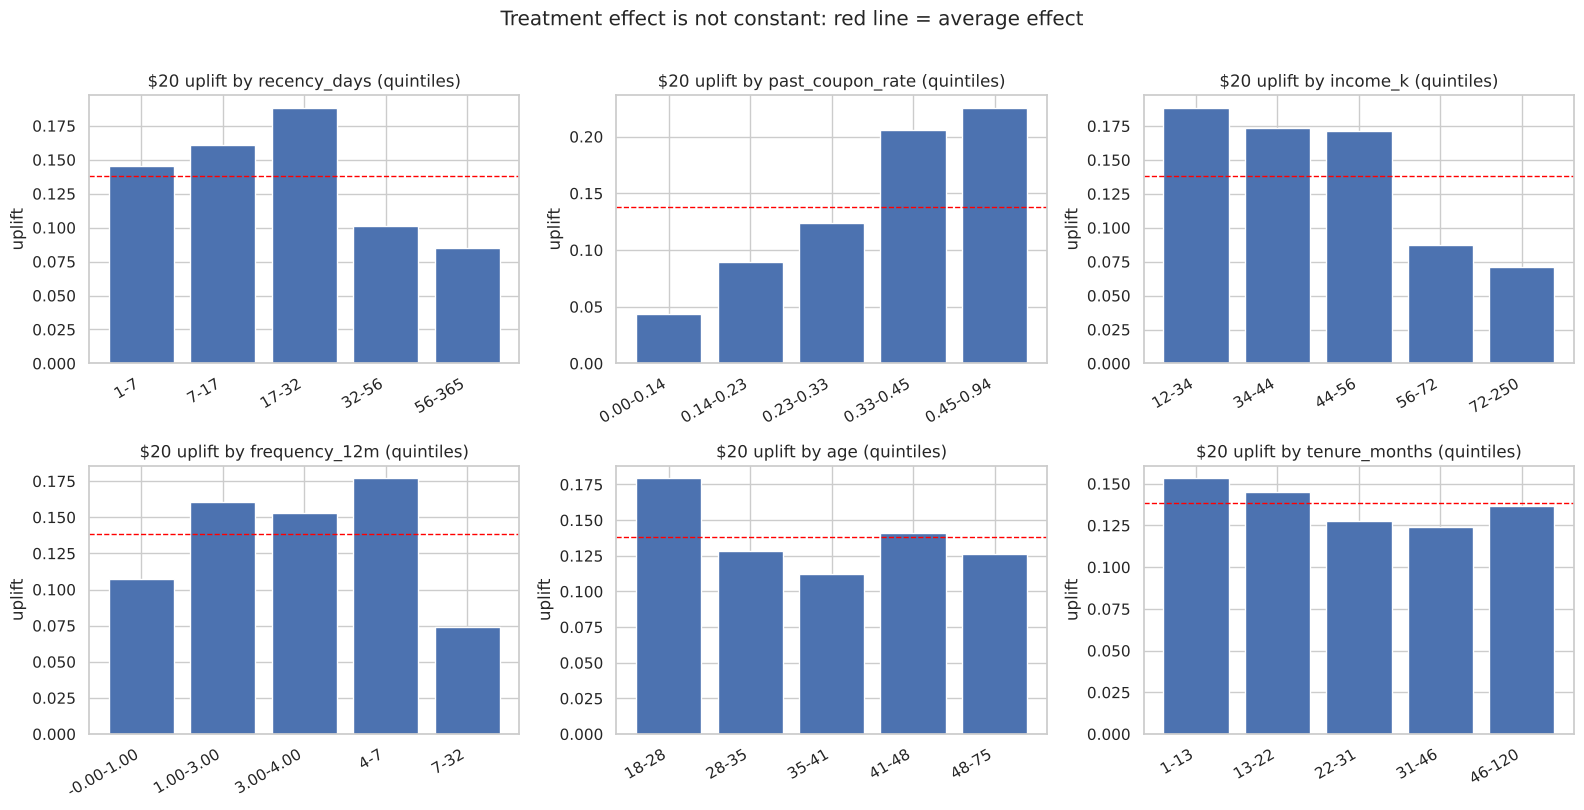

In [17]:
def uplift_by_bin(df, col, arm=20, q=5):
    d = df[df[T].isin([0, arm])].copy()
    d["bin"] = pd.qcut(d[col], q, duplicates="drop")
    g = d.groupby(["bin", T], observed=True)[Y].mean().unstack()
    return (g[arm] - g[0]).rename("uplift")

cols = ["recency_days", "past_coupon_rate", "income_k", "frequency_12m", "age", "tenure_months"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cols):
    u = uplift_by_bin(rct, col)
    ax.bar(range(len(u)), u.values, color="#4C72B0")
    ax.set_xticks(range(len(u)))
    ax.set_xticklabels([f"{i.left:.0f}-{i.right:.0f}" if abs(i.right) > 5 else f"{i.left:.2f}-{i.right:.2f}" for i in u.index],
                       rotation=30, ha="right")
    ax.axhline(rct[rct[T] == 20][Y].mean() - rct[rct[T] == 0][Y].mean(), color="red", ls="--", lw=1)
    ax.set_title(f"$20 uplift by {col} (quintiles)")
    ax.set_ylabel("uplift")
plt.suptitle("Treatment effect is not constant: red line = average effect", y=1.01)
plt.tight_layout(); plt.show()

,feature,level,n,uplift
9,channel,referral,1094,0.1749
3,device,desktop,3962,0.1662
2,loyalty_tier,Silver,3782,0.1595
12,region,East,2631,0.1520
5,device,tablet,1044,0.1510
15,region,West,2941,0.1500
8,channel,paid_search,3018,0.1439
7,channel,organic,3964,0.1421
11,region,Central,1559,0.1380
6,channel,email,2661,0.1375


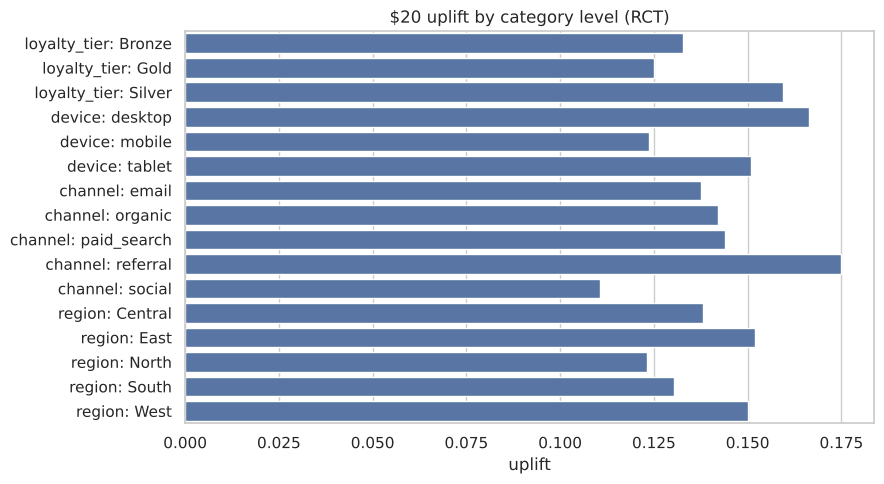

In [18]:
# Effect by categorical features (RCT, $20 vs $0)
rows = []
for col in CAT:
    for lvl, d in rct[rct[T].isin([0, 20])].groupby(col):
        a, b = d[d[T] == 0][Y].mean(), d[d[T] == 20][Y].mean()
        rows.append({"feature": col, "level": lvl, "n": len(d), "uplift": b - a})
cat_up = pd.DataFrame(rows)
display(cat_up.round(4).sort_values("uplift", ascending=False).head(10))
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=cat_up, y=cat_up["feature"] + ": " + cat_up["level"], x="uplift", color="#4C72B0", ax=ax)
ax.set_ylabel(""); ax.set_title("$20 uplift by category level (RCT)")
plt.tight_layout(); plt.show()

The uplift changes strongly with features like recency and coupon behaviour. That variation is the whole reason to estimate **individual** treatment effects (ITE):
a single average hides who is persuadable.

## 9. Ground truth: individual effects and segments (simulated data only)

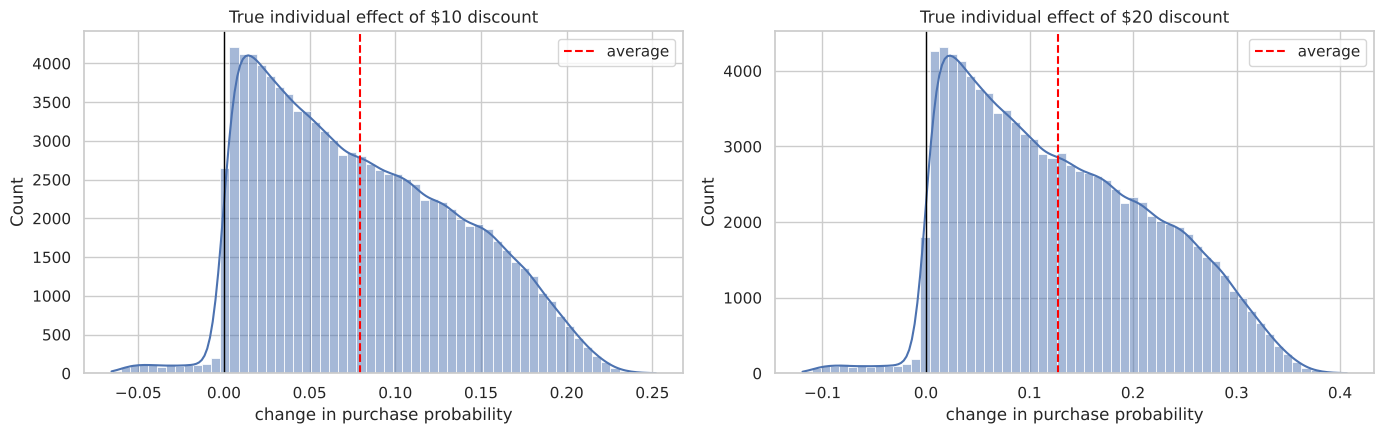

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, arm in zip(axes, [10, 20]):
    sns.histplot(obs[f"gt_ite_{arm}"], bins=60, kde=True, ax=ax, color="#4C72B0")
    ax.axvline(0, color="black", lw=1)
    ax.axvline(obs[f"gt_ite_{arm}"].mean(), color="red", ls="--", label="average")
    ax.set_title(f"True individual effect of ${arm} discount")
    ax.set_xlabel("change in purchase probability"); ax.legend()
plt.tight_layout(); plt.show()

In [20]:
seg_order = ["Persuadable", "Sure Thing", "Lost Cause", "Sleeping Dog"]
seg_share = obs["gt_segment"].value_counts(normalize=True).reindex(seg_order)
display((seg_share * 100).round(1).rename("share %"))

profile = (obs.groupby("gt_segment")[["gt_p_no_discount", "gt_ite_10", "gt_ite_20",
                                      "recency_days", "frequency_12m", "past_coupon_rate", "income_k"]]
           .mean().reindex(seg_order).round(3))
display(profile)

gt_segment
Persuadable     50.0
Sure Thing      14.5
Lost Cause      34.5
Sleeping Dog     1.0
Name: share %, dtype: float64

,gt_p_no_discount,gt_ite_10,gt_ite_20,recency_days,frequency_12m,past_coupon_rate,income_k
gt_segment,,,,,,,
Persuadable,0.195,0.124,0.200,27.105,3.519,0.383,45.042
Sure Thing,0.703,0.051,0.082,15.990,10.553,0.315,55.500
Lost Cause,0.144,0.030,0.048,53.671,2.868,0.195,66.885
Sleeping Dog,0.781,-0.035,-0.066,18.150,12.237,0.085,69.575


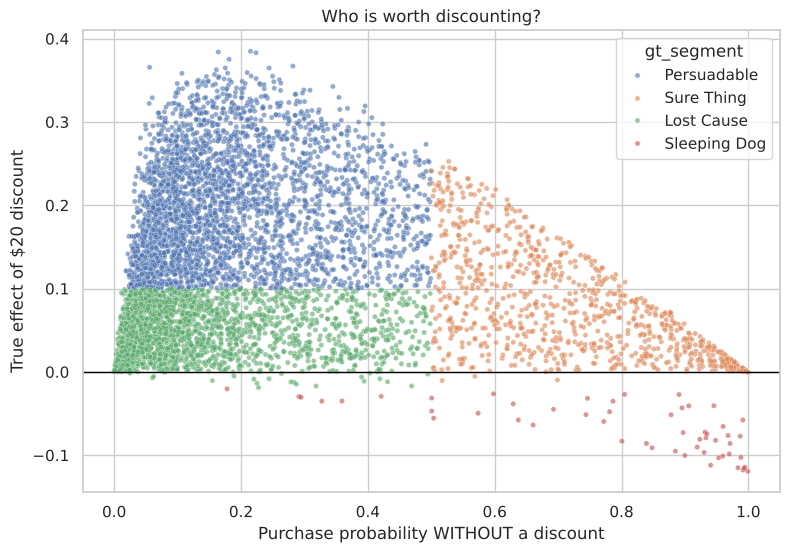

In [21]:
sample = obs.sample(6000, random_state=1)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=sample, x="gt_p_no_discount", y="gt_ite_20", hue="gt_segment",
                hue_order=seg_order, s=14, alpha=0.6)
plt.axhline(0, color="black", lw=1)
plt.xlabel("Purchase probability WITHOUT a discount")
plt.ylabel("True effect of $20 discount")
plt.title("Who is worth discounting?")
plt.show()

**This picture is the heart of the project:**
- **Persuadables** (low baseline probability, high uplift) are where the budget should go.
- **Sure Things** (high baseline probability) buy anyway, so a discount is wasted money.
- **Lost Causes** barely react, so a discount is wasted money.
- **Sleeping Dogs** (a small group) buy *less* when given a discount, so they should be excluded.
A normal churn or purchase model ranks Sure Things highest, which is the mistake EconoCausal fixes.

## 10. Key findings and next steps

Fill in the numbers from your own run:

1. **Data quality:** no missing values or duplicates; 100,000 observational and 20,000 RCT customers.
2. **Confounding is real:** the observational discount groups differ strongly on recency and coupon use (Section 5), so naive comparisons are biased (Section 7).
3. **Overlap is adequate:** every customer type had a reasonable chance of each discount (Section 6).
4. **Effects are heterogeneous:** uplift varies a lot by recency, coupon use, income and loyalty (Section 8).
5. **Segments:** roughly half of customers are Persuadables; a small group are Sleeping Dogs (Section 9).

**Next steps:**
- Train DML (EconML `LinearDML` / `CausalForestDML`) on the observational file, using the features only.
- Validate against the RCT and the `gt_ite_*` columns.
- Feed predicted individual effects into the SciPy budget optimizer.